# Novelty scores + regime classifier confidence: do they classify the regimes better together?

Notebook 06's regime classifier gives each window a probability for each regime; notebooks 05 and 07 give every
autoencoder's novelty scores. This notebook stacks them: the classifier's (out-of-fold) probabilities plus each model
type's best novelty scores, fed to a second model, and asks whether ID-safe, OOD-safe and OOD-dangerous are told apart
better than by the classifier alone.

| feature | what | chosen how |
|---|---|---|
| regime confidence | notebook 06's classifier (boosted trees on TCN-VAE latent + LSTM-VAE novelty + rhythm), its three probabilities after the 0.5 s causal median | on the validation participants, out of fold (leave one participant out), so the second model never sees probabilities fitted on its own windows |
| novelty, unfamiliar | per model type (ID-trained), the cell and score with the best validation AUROC for unfamiliar against familiar | `results/05_native_scores.csv` |
| novelty, dangerous | per model type (ID-trained), the cell and score with the best validation AUROC for dangerous against OOD-safe | `results/07_train_class_best.csv` |

Fitted on the validation participants (configurations compared by leave-one-participant-out cross-validation), test
participants scored once, three seeds (each seed's runs and classifier together); held out: each dangerous task left out
of both stages in turn. Results to `results/09_*.csv`, figures to `figures/09_*.png`.

## Findings at a glance

- **Stacking novelty onto the regime classifier does not help.** Test macro F1: classifier alone 0.868 ± 0.005; with each
  model type's best novelty scores, boosted trees 0.856 ± 0.002, logistic 0.831 ± 0.010; novelty alone 0.824 ± 0.010. The
  classifier already carries the LSTM-VAE's novelty; the other model types' scores add little that is new. Logistic
  stacking buys dangerous recall (0.86 vs 0.79) by switching off twice the safe windows (5.6% vs 2.8%).
- **One uncertainty score orders the regimes as wanted.** $u = 0.5\,p_\text{OOD-safe} + p_\text{dangerous}$ from the
  classifier alone: ID-safe sits at 0, OOD-safe at 0.5, dangerous towards 1 (test AUROC 0.981 ID-safe vs OOD-safe, 0.965
  OOD-safe vs dangerous). Cutoffs chosen on validation (0.25 and 0.825) give the same macro F1 as the classifier (0.868),
  no dangerous window on the spline, and 2.1% of safe windows switched off.
- **The cost is the dangerous windows the classifier is unsure of.** They spread over 0.5 to 0.8, inside the estimator
  band: 24% of dangerous windows still get some torque (30 to 70% of it). Pushing that to about 5% means switching off
  roughly 15 to 20% of safe windows (the trade-off panel).
- **Inside the estimator band, $u$ barely varies.** Nearly every OOD-safe task has a median of 0.50 to 0.52 (interquartile
  ranges within 0.50 to 0.56; squats reach 0.80, obstacle walk and curb up drop towards ID). The classifier is
  confident about *which* regime, so $u$ says little about *how* unfamiliar an OOD-safe window is, and the ramp gives
  most of them the same ~68% torque.
- **A dangerous task no stage saw** (each left out of both stages): almost never on the spline (≤0.2%), but only 16 to
  25% lands right of the exo-off cutoff; most goes to the estimator (median $u$ 0.58 for the classifier alone, mean
  torque 50%). Step-ups are the worst (median 0.50, 1% switched off); sit-to-stand the best (39%).
- **Ramping the estimator's torque on a novelty score grades OOD-safe but orders it worse** (section 5). The score chosen
  on validation, the LSTM-VAE's posterior variance, spreads OOD-safe torque widely (interquartile range 0.70 vs 0.01 for
  $u$), but in the band it orders OOD-safe above dangerous only at AUROC 0.74 (0.89 for $u$). Ramping on the classifier's
  $p_\text{dangerous}$ is the best compromise: OOD-safe gets the most torque (0.82 vs 0.68), in-band dangerous the least
  (0.43 vs 0.56), ordering 0.87, interquartile range 0.27. On unseen dangerous tasks the novelty ramp cuts mean torque from
  0.50 to 0.35 (step-ups 0.68 → 0.56).

In [1]:
import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'ml' / 'nature' / 'nature_data.py').exists())
for folder in ('ml/common', 'ml/nature', 'notebooks/nature/model_exploration/onboard'):
    if str(REPO / folder) not in sys.path:
        sys.path.insert(0, str(REPO / folder))
import _novelty_scores as ns
import _regime_classifier as rc

ROOT = REPO / 'notebooks' / 'nature' / 'model_exploration'
DATA = REPO / 'data' / 'processed_nature' / 'ae'
CACHE = REPO / 'data' / 'cache' / 'nature' / 'novelty'
RESULTS, FIG_DIR = Path.cwd() / 'results', Path.cwd() / 'figures'
SEEDS = (0, 1, 2)
ENCODER = ROOT / 'runs_train_class' / 'id_ood_safe' / 'vae' / 'tcn_vae_raw_3s_spectral_b128_fixed_s{seed}'
DETECTOR = ROOT / 'runs' / 'vae' / 'lstm_vae_raw_3s_b1_fixed_s{seed}'
BASE_NOVELTY = ['LOF, raw latent', 'Mahalanobis, latent', 'posterior variance']
pd.set_option('display.width', 220)

meta = json.loads((DATA / 'meta.json').read_text())
tables = {inputs: pd.read_parquet(DATA / spec['table']) for inputs, spec in meta['inputs'].items()}
rows = {split: rc.get_split_rows(tables['raw_3s'], split) for split in ('val', 'test')}
keys = {split: r[['rec', 'end']] for split, r in rows.items()}
y = {split: r['controller_class'].astype(str).to_numpy() for split, r in rows.items()}
subjects = rows['val']['subject'].astype(str).to_numpy()
runs = ns.discover_runs(ROOT / 'runs')
runs['type'] = runs['config'].map(ns.get_model_type)
print(f'{len(y["val"]):,} validation and {len(y["test"]):,} test windows; {len(runs)} ID-trained runs')

173,590 validation and 137,955 test windows; 258 ID-trained runs


## 1. Each model type's best novelty scores

In [2]:
native = pd.read_csv(RESULTS / '05_native_scores.csv').merge(runs.drop_duplicates('model')[['model', 'type']], on = 'model')
v_unf = native.groupby(['type', 'model', 'score'])['val AUROC, unfamiliar vs familiar'].mean()
pick_unf = v_unf.loc[v_unf.groupby('type').idxmax()].reset_index().assign(target = 'unfamiliar')
best07 = pd.read_csv(RESULTS / '07_train_class_best.csv')
best07 = best07[best07['train_class'] == 'ID-safe']
pick_dang = best07.loc[best07.groupby('type')['val AUROC, dangerous vs OOD-safe mean'].idxmax(), ['type', 'model', 'score', 'val AUROC, dangerous vs OOD-safe mean']].assign(target = 'dangerous')
picks = pd.concat([pick_unf, pick_dang], ignore_index = True).drop_duplicates(['model', 'score'])
display(picks[['target', 'type', 'model', 'score']].sort_values(['target', 'type']))
NOVELTY_NAMES = [f'{r.type}: {r.score} ({r.target})' for r in picks.itertuples()]
print(len(picks), 'novelty features')

,target,type,model,score
7,dangerous,Gaussian-NLL AE,gaussian · 3 s + spectral,out-of-range units
8,dangerous,LSTM-VAE,LSTM-VAE · β 1 · fixed variance · 3 s + spectral,posterior variance
9,dangerous,TCN-VAE,TCN-VAE · β 1 · fixed variance · 3 s + spectral,out-of-range units
10,dangerous,Transformer VAE,Transformer VAE · β 1 · fixed variance · 3 s +...,posterior variance
11,dangerous,conv VAE,VAE · β 1 · learned variance · 3 s raw,KL
12,dangerous,plain AE,vanilla · 3 s + spectral · 8x4,"Mahalanobis, latent"
13,dangerous,sparse AE,sparse · 3 s + spectral · λ 0.1 · 8x4,"Mahalanobis, latent"
0,unfamiliar,Gaussian-NLL AE,gaussian · 3 s raw,"LOF, raw latent"
1,unfamiliar,LSTM-VAE,LSTM-VAE · β 1 · fixed variance · 3 s raw,"LOF, raw latent"
2,unfamiliar,TCN-VAE,TCN-VAE · β 1 · fixed variance · 3 s raw,"LOF, raw latent"


14 novelty features


## 2. Features per seed: novelty scores and the regime classifier's out-of-fold probabilities

In [3]:
def get_base_x(seed: int) -> dict[str, np.ndarray]:
    # notebook 06's chosen features: TCN-VAE latent + LSTM-VAE novelty + rhythm
    latent = rc.get_latents(Path(str(ENCODER).format(seed = seed)), tables['raw_3s_spectral'], keys)
    nov = rc.get_novelty(Path(str(DETECTOR).format(seed = seed)), tables['raw_3s'], keys, BASE_NOVELTY, CACHE)
    return {s: np.concatenate([latent[s], nov[s], rows[s][rc.RHYTHM].to_numpy(dtype = np.float64)], axis = 1) for s in ('val', 'test')}


def get_novelty_x(seed: int) -> dict[str, np.ndarray]:
    # each picked (model, score) of this seed, as columns
    cols = {'val': [], 'test': []}
    for r in picks.itertuples():
        run = runs[(runs['model'] == r.model) & (runs['seed'] == seed)].iloc[0]
        out = rc.get_novelty(run['run'], tables[run['inputs']], keys, [r.score], CACHE)
        cols['val'].append(out['val']); cols['test'].append(out['test'])
    return {s: np.concatenate(c, axis = 1) for s, c in cols.items()}


def get_proba(x_fit, y_fit, x, labels, seed) -> np.ndarray:
    # the regime classifier's smoothed probabilities in REGIMES order
    model = HistGradientBoostingClassifier(class_weight = 'balanced', max_iter = 300, random_state = seed).fit(x_fit, y_fit)
    p = pd.DataFrame(model.predict_proba(x), columns = model.classes_).reindex(columns = list(rc.REGIMES), fill_value = 0).to_numpy()
    return rc.get_smoothed(p, labels)


def get_oof_proba(x_v, fit_mask, seed) -> np.ndarray:
    # out-of-fold probabilities on the validation windows: each participant from a classifier fitted on the other three
    out = np.zeros((len(x_v), len(rc.REGIMES)))
    for person in np.unique(subjects):
        held = subjects == person
        out[held] = get_proba(x_v[fit_mask & ~held], y['val'][fit_mask & ~held], x_v[held], rows['val'][held].reset_index(drop = True), seed)
    return out


t0 = time.time()
base, novelty, oof, test_proba = {}, {}, {}, {}
everything = np.ones(len(y['val']), bool)
for seed in SEEDS:
    base[seed], novelty[seed] = get_base_x(seed), get_novelty_x(seed)
    oof[seed] = get_oof_proba(base[seed]['val'], everything, seed)
    test_proba[seed] = get_proba(base[seed]['val'], y['val'], base[seed]['test'], rows['test'], seed)
print(f'{time.time() - t0:.0f} s')

189 s


## 3. Classifier alone against the stacked models

Every configuration predicts the regime; cross-validated on the validation participants (out-of-fold probabilities are
their input there) and scored once on the test participants.

In [4]:
SECOND = {'boosted trees': lambda s: HistGradientBoostingClassifier(class_weight = 'balanced', max_iter = 300, random_state = s),
          'logistic': lambda s: make_pipeline(StandardScaler(), LogisticRegression(class_weight = 'balanced', max_iter = 3000))}
CONFIGS = {'regime classifier alone': (None, None), 'novelty scores alone': ('novelty', 'boosted trees'),
           'confidence + novelty (boosted trees)': ('both', 'boosted trees'), 'confidence + novelty (logistic)': ('both', 'logistic')}


def get_x(seed, split, kind, proba) -> np.ndarray:
    return novelty[seed][split] if kind == 'novelty' else np.concatenate([proba, novelty[seed][split]], axis = 1)


def get_second_proba(model, x_fit, y_fit, x, labels) -> np.ndarray:
    # the second model's smoothed probabilities in REGIMES order
    model.fit(x_fit, y_fit)
    p = pd.DataFrame(model.predict_proba(x), columns = model.classes_).reindex(columns = list(rc.REGIMES), fill_value = 0).to_numpy()
    return rc.get_smoothed(p, labels)


def get_pred(proba: np.ndarray) -> np.ndarray:
    return np.array(rc.REGIMES)[proba.argmax(axis = 1)]


t0 = time.time()
result, val_p, test_p = [], {}, {}             # (seed, configuration) -> smoothed probabilities, out of fold on validation
for seed in SEEDS:
    for name, (kind, second) in CONFIGS.items():
        cv, val_p[seed, name] = [], np.zeros((len(y['val']), len(rc.REGIMES)))
        for person in np.unique(subjects):
            held = subjects == person
            lab = rows['val'][held].reset_index(drop = True)
            if kind is None:
                val_p[seed, name][held] = oof[seed][held]
            else:
                x_v = get_x(seed, 'val', kind, oof[seed])
                val_p[seed, name][held] = get_second_proba(SECOND[second](seed), x_v[~held], y['val'][~held], x_v[held], lab)
            cv.append(rc.get_regime_metrics(y['val'][held], get_pred(val_p[seed, name][held]))['macro F1'])
        if kind is None:
            test_p[seed, name] = test_proba[seed]
        else:
            test_p[seed, name] = get_second_proba(SECOND[second](seed), get_x(seed, 'val', kind, oof[seed]), y['val'],
                                                  get_x(seed, 'test', kind, test_proba[seed]), rows['test'])
        pred_t = get_pred(test_p[seed, name])
        result.append({'configuration': name, 'seed': seed, 'CV macro F1 (validation)': np.mean(cv),
                       **{f'test {k}': v for k, v in rc.get_regime_metrics(y['test'], pred_t).items()}})
scores = pd.DataFrame(result)
scores.to_csv(RESULTS / '09_fusion_scores.csv', index = False)
summary = scores.drop(columns = 'seed').groupby('configuration', sort = False).agg(['mean', 'std'])
display(pd.DataFrame({c: summary[(c, 'mean')].map('{:.3f}'.format) + ' ± ' + summary[(c, 'std')].map('{:.3f}'.format)
                      for c in scores.columns if c not in ('configuration', 'seed')}).T)
print(f'{time.time() - t0:.0f} s')

configuration,regime classifier alone,novelty scores alone,confidence + novelty (boosted trees),confidence + novelty (logistic)
CV macro F1 (validation),0.863 ± 0.003,0.826 ± 0.006,0.839 ± 0.006,0.834 ± 0.006
test macro F1,0.868 ± 0.005,0.824 ± 0.010,0.856 ± 0.002,0.831 ± 0.010
"test recall, ID-safe",0.929 ± 0.009,0.934 ± 0.021,0.934 ± 0.008,0.946 ± 0.005
"test recall, OOD-safe",0.917 ± 0.009,0.881 ± 0.007,0.905 ± 0.012,0.849 ± 0.016
"test recall, OOD-dangerous",0.794 ± 0.009,0.727 ± 0.044,0.769 ± 0.042,0.858 ± 0.014
test dangerous sent to the spline (%),0.000 ± 0.000,0.000 ± 0.000,0.020 ± 0.035,0.020 ± 0.025
test safe switched off (%),2.798 ± 0.140,4.240 ± 0.198,2.503 ± 0.370,5.567 ± 1.317


234 s


## 4. One uncertainty score: ID-safe left, OOD-safe in the middle, OOD-dangerous right

Each configuration's three probabilities collapse to one number, the window's expected place on the regime axis:

$$u = 0 \cdot p_\text{ID-safe} + 0.5 \cdot p_\text{OOD-safe} + 1 \cdot p_\text{OOD-dangerous} \in [0, 1].$$

Two cutoffs split it into the three controllers. They are chosen on the validation participants' out-of-fold scores
(three seeds pooled, best macro F1 over every pair on a 0.005 grid) and then fixed for test. Inside the estimator band
the torque is scaled down as $u$ rises, linearly from full at the first cutoff to `JME_FLOOR` just before the second;
from the second cutoff the exo is off. The ramp is a placeholder until the estimator's error is measured against $u$.

In [5]:
JME_FLOOR = 0.3                                  # share of the estimator's torque kept just below the exo-off cutoff
y_val_all, y_test_all = np.tile(y['val'], len(SEEDS)), np.tile(y['test'], len(SEEDS))
u_val = {name: np.concatenate([rc.get_uncertainty(val_p[s, name]) for s in SEEDS]) for name in CONFIGS}
u_test = {name: np.concatenate([rc.get_uncertainty(test_p[s, name]) for s in SEEDS]) for name in CONFIGS}
cutoffs = {name: rc.get_cutoffs(u_val[name], y_val_all) for name in CONFIGS}

unc_rows = []
for name in CONFIGS:
    for seed in SEEDS:
        u = rc.get_uncertainty(test_p[seed, name])
        m = rc.get_regime_metrics(y['test'], rc.get_banded(u, cutoffs[name]))
        gain = rc.get_assistance(u, cutoffs[name], JME_FLOOR)
        is_id, is_safe, is_dang = (y['test'] == r for r in rc.REGIMES)
        unc_rows.append({'configuration': name, 'seed': seed, 'cutoff, spline | estimator': cutoffs[name][0],
                         'cutoff, estimator | off': cutoffs[name][1],
                         'AUROC, ID-safe vs OOD-safe': roc_auc_score(is_safe[is_id | is_safe], u[is_id | is_safe]),
                         'AUROC, OOD-safe vs dangerous': roc_auc_score(is_dang[is_safe | is_dang], u[is_safe | is_dang]),
                         'test macro F1 (cutoffs)': m['macro F1'], 'dangerous sent to the spline (%)': m['dangerous sent to the spline (%)'],
                         'safe switched off (%)': m['safe switched off (%)'],
                         'mean assistance, OOD-safe': gain[is_safe].mean(), 'mean assistance, dangerous': gain[is_dang].mean(),
                         'dangerous given any torque (%)': 100 * np.mean(gain[is_dang] > 0)})
unc = pd.DataFrame(unc_rows)
unc.to_csv(RESULTS / '09_uncertainty_scores.csv', index = False)
s = unc.drop(columns = 'seed').groupby('configuration', sort = False).agg(['mean', 'std'])
display(pd.DataFrame({c: s[(c, 'mean')].map('{:.3f}'.format) + ' ± ' + s[(c, 'std')].map('{:.3f}'.format)
                      for c in unc.columns if c not in ('configuration', 'seed')}).T)
CHOSEN = max(CONFIGS, key = lambda n: rc.get_regime_metrics(y_val_all, rc.get_banded(u_val[n], cutoffs[n]))['macro F1'])
print('chosen on validation:', CHOSEN, '| cutoffs', cutoffs[CHOSEN])

configuration,regime classifier alone,novelty scores alone,confidence + novelty (boosted trees),confidence + novelty (logistic)
"cutoff, spline | estimator",0.250 ± 0.000,0.230 ± 0.000,0.420 ± 0.000,0.215 ± 0.000
"cutoff, estimator | off",0.825 ± 0.000,0.850 ± 0.000,0.925 ± 0.000,0.945 ± 0.000
"AUROC, ID-safe vs OOD-safe",0.981 ± 0.003,0.983 ± 0.003,0.986 ± 0.002,0.979 ± 0.001
"AUROC, OOD-safe vs dangerous",0.965 ± 0.000,0.941 ± 0.012,0.963 ± 0.006,0.957 ± 0.001
test macro F1 (cutoffs),0.868 ± 0.005,0.826 ± 0.011,0.835 ± 0.007,0.854 ± 0.004
dangerous sent to the spline (%),0.000 ± 0.000,0.000 ± 0.000,0.020 ± 0.035,0.000 ± 0.000
safe switched off (%),2.067 ± 0.134,2.606 ± 0.253,1.182 ± 0.278,2.051 ± 0.131
"mean assistance, OOD-safe",0.681 ± 0.001,0.674 ± 0.005,0.865 ± 0.005,0.674 ± 0.008
"mean assistance, dangerous",0.135 ± 0.003,0.188 ± 0.027,0.223 ± 0.035,0.129 ± 0.011
dangerous given any torque (%),24.238 ± 0.473,34.526 ± 4.526,33.131 ± 3.899,25.627 ± 2.064


chosen on validation: regime classifier alone | cutoffs (0.25, 0.8250000000000001)


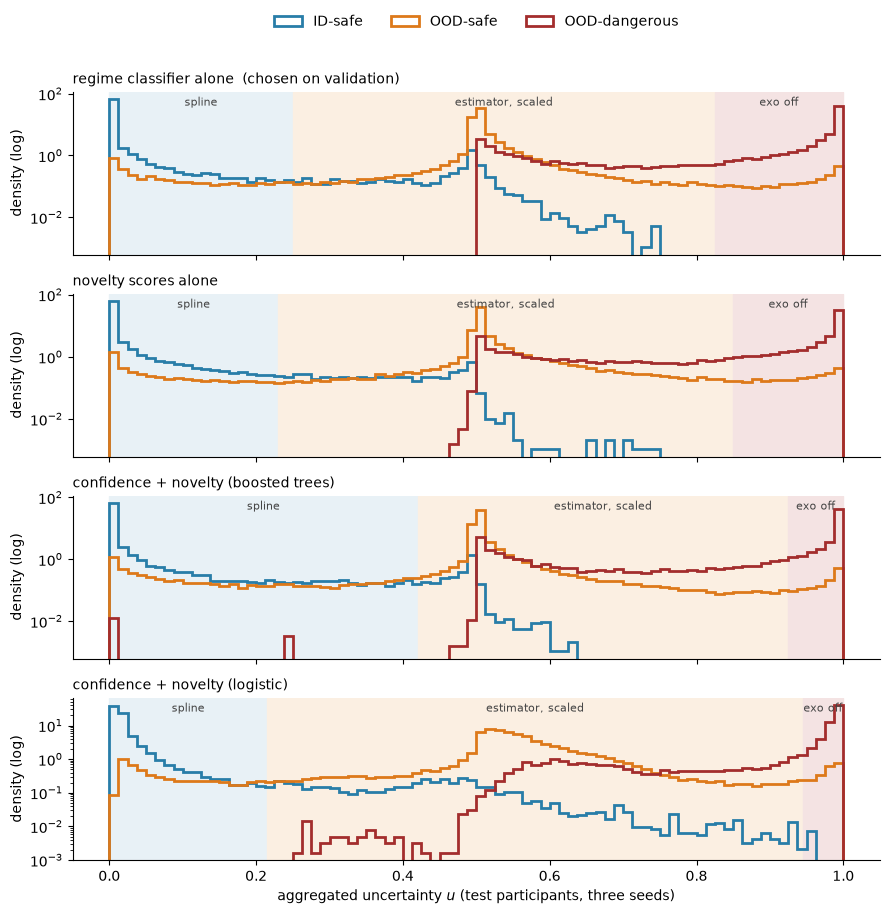

In [6]:
REGIME_C = dict(zip(rc.REGIMES, ['#287da8', '#dd791a', '#a32d2d']))     # notebook 01's controller-class colours
BAND = [('spline', '#e8f1f6'), ('estimator, scaled', '#fbefe2'), ('exo off', '#f4e3e3')]
bins = np.linspace(0, 1, 81)
fig, axes = plt.subplots(len(CONFIGS), 1, figsize = (9, 2.3 * len(CONFIGS)), sharex = True)
for ax, name in zip(axes, CONFIGS):
    edges = [0, *cutoffs[name], 1]
    for k, (band, colour) in enumerate(BAND):
        ax.axvspan(edges[k], edges[k + 1], color = colour, zorder = 0)
        ax.text((edges[k] + edges[k + 1]) / 2, .97, band, transform = ax.get_xaxis_transform(), ha = 'center', va = 'top', fontsize = 8, color = '#444')
    for r in rc.REGIMES:
        ax.hist(u_test[name][y_test_all == r], bins = bins, density = True, histtype = 'step', linewidth = 2, color = REGIME_C[r], label = r)
    ax.set_yscale('log')
    ax.set_ylabel('density (log)')
    ax.set_title(f'{name}{"  (chosen on validation)" if name == CHOSEN else ""}', fontsize = 10, loc = 'left')
    ax.spines[['top', 'right']].set_visible(False)
axes[0].legend(loc = 'upper center', bbox_to_anchor = (.5, 1.55), ncol = 3, frameon = False)
axes[-1].set_xlabel('aggregated uncertainty $u$ (test participants, three seeds)')
fig.tight_layout()
fig.savefig(FIG_DIR / '09_uncertainty_score.png', dpi = 160, bbox_inches = 'tight')
plt.show()

The chosen score in controller terms: the assistance it gives (left), the assistance each regime's windows actually
receive (middle), and the trade-off of moving the exo-off cutoff (right, the first cutoff fixed; the dot is the cutoff
chosen on validation).

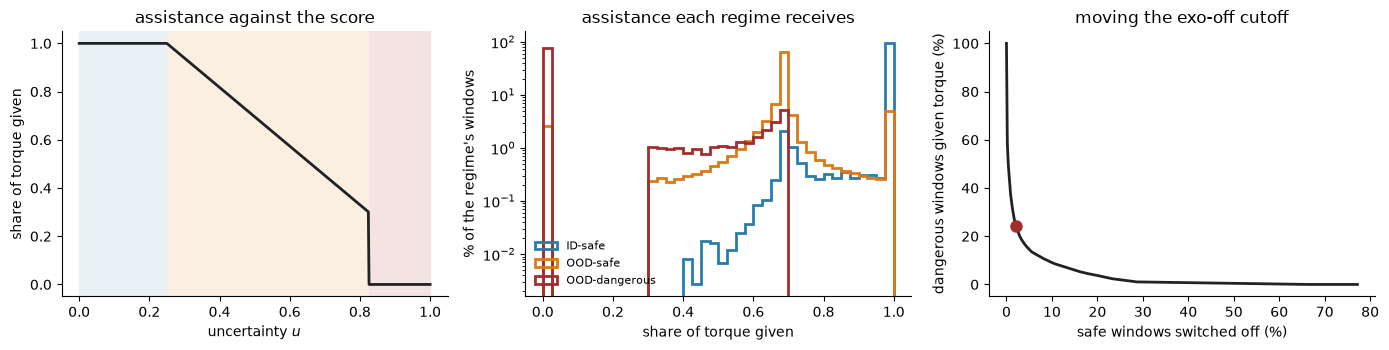

In [7]:
u_c, t1, t2 = u_test[CHOSEN], *cutoffs[CHOSEN]
fig, axes = plt.subplots(1, 3, figsize = (14, 3.6))
grid = np.linspace(0, 1, 501)
axes[0].plot(grid, rc.get_assistance(grid, cutoffs[CHOSEN], JME_FLOOR), color = '#222', linewidth = 2)
for k, (band, colour) in enumerate(BAND):
    axes[0].axvspan([0, t1, t2][k], [t1, t2, 1][k], color = colour, zorder = 0)
axes[0].set(xlabel = 'uncertainty $u$', ylabel = 'share of torque given', title = 'assistance against the score')
gain = rc.get_assistance(u_c, cutoffs[CHOSEN], JME_FLOOR)
for r in rc.REGIMES:
    axes[1].hist(gain[y_test_all == r], bins = np.linspace(0, 1, 41), weights = np.full((y_test_all == r).sum(), 100 / (y_test_all == r).sum()),
                 histtype = 'step', linewidth = 2, color = REGIME_C[r], label = r)
axes[1].set(xlabel = 'share of torque given', ylabel = "% of the regime's windows", title = 'assistance each regime receives', yscale = 'log')
axes[1].legend(frameon = False, fontsize = 8)
sweep = np.linspace(t1, 1, 200)
safe, dang = np.isin(y_test_all, (ns.ID, ns.SAFE)), y_test_all == ns.DANGEROUS
off_safe = [100 * np.mean(u_c[safe] >= c) for c in sweep]
on_dang = [100 * np.mean(u_c[dang] < c) for c in sweep]
axes[2].plot(off_safe, on_dang, color = '#222', linewidth = 2)
axes[2].plot(100 * np.mean(u_c[safe] >= t2), 100 * np.mean(u_c[dang] < t2), 'o', color = REGIME_C[ns.DANGEROUS], markersize = 8)
axes[2].set(xlabel = 'safe windows switched off (%)', ylabel = 'dangerous windows given torque (%)', title = 'moving the exo-off cutoff')
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / '09_uncertainty_assistance.png', dpi = 160, bbox_inches = 'tight')
plt.show()

Per task (test participants, chosen score): the median and interquartile range of $u$, coloured by the task's regime.

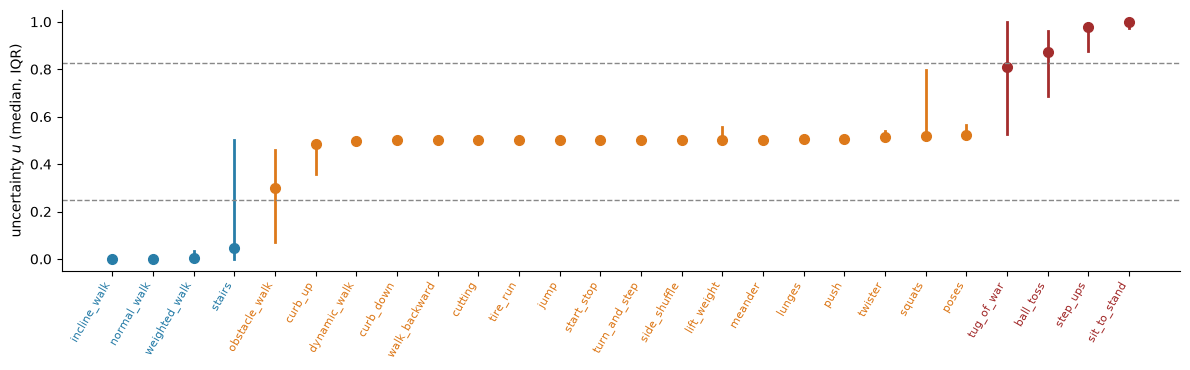

In [8]:
frame = pd.DataFrame({'task': np.tile(rows['test']['task'].astype(str).to_numpy(), len(SEEDS)), 'regime': y_test_all, 'u': u_c})
per = frame.groupby(['task', 'regime'])['u'].describe()[['25%', '50%', '75%']].reset_index().sort_values('50%')
per.to_csv(RESULTS / '09_uncertainty_per_task.csv', index = False)
fig, ax = plt.subplots(figsize = (12, 3.8))
for k, t in enumerate(per.itertuples()):
    ax.plot([k, k], [t._3, t._5], color = REGIME_C[t.regime], linewidth = 2)
    ax.plot(k, t._4, 'o', color = REGIME_C[t.regime], markersize = 7)
for c in cutoffs[CHOSEN]:
    ax.axhline(c, color = '#888', linestyle = '--', linewidth = 1)
ax.set_xticks(range(len(per)), per['task'], rotation = 60, ha = 'right', fontsize = 8)
for k, t in enumerate(per.itertuples()):
    ax.get_xticklabels()[k].set_color(REGIME_C[t.regime])
ax.set_ylabel('uncertainty $u$ (median, IQR)')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / '09_uncertainty_per_task.png', dpi = 160, bbox_inches = 'tight')
plt.show()

## 5. Ramping the estimator's torque on a novelty score

Section 4's $u$ sits near 0.5 for almost every OOD-safe window, so a ramp in $u$ is nearly constant. Here the band is still
set by $u$ (same cutoffs: spline below 0.25, exo off from 0.825), but *inside* it the torque follows a novelty score:
full up to the median of the validation OOD-safe windows in the band, falling linearly to `JME_FLOOR` at the median of
the validation dangerous windows in the band, held there above.

The signal is chosen on the validation participants: of the novelty scores picked in section 1, the one whose in-band
AUROC for dangerous against OOD-safe is highest (mean over seeds, each seed's own runs; oriented so higher is less
familiar). The classifier's own $p_\text{dangerous}$ is ramped the same way for comparison.

In [9]:
def get_band(u: np.ndarray) -> np.ndarray:
    return (u >= cutoffs[CHOSEN][0]) & (u < cutoffs[CHOSEN][1])


def get_signals(seed: int, split: str, p: np.ndarray) -> np.ndarray:
    # candidate ramp signals: each picked novelty score, then p(dangerous). (N, S + 1)
    return np.concatenate([novelty[seed][split], p[:, 2:3]], axis = 1)


SIGNALS = NOVELTY_NAMES + ['p(dangerous), regime classifier']
p_val = {seed: val_p[seed, CHOSEN] for seed in SEEDS}
p_test = {seed: test_p[seed, CHOSEN] for seed in SEEDS}
auc_rows = []
for seed in SEEDS:
    band = get_band(rc.get_uncertainty(p_val[seed]))
    sig, lab = get_signals(seed, 'val', p_val[seed])[band], y['val'][band]
    keep = lab != ns.ID
    for j, name in enumerate(SIGNALS):
        auc_rows.append({'signal': name, 'seed': seed, 'AUROC': roc_auc_score(lab[keep] == ns.DANGEROUS, sig[keep, j])})
auc = pd.DataFrame(auc_rows).groupby('signal', sort = False)['AUROC'].mean()
sign = np.where(auc >= .5, 1.0, -1.0)                      # orient every signal so higher means less familiar
selection = pd.DataFrame({'val AUROC in band, dangerous vs OOD-safe (oriented)': np.maximum(auc, 1 - auc), 'orientation': sign})
display(selection.sort_values(selection.columns[0], ascending = False).round(3))
best_j = int(np.argmax(np.maximum(auc, 1 - auc).to_numpy()[:len(NOVELTY_NAMES)]))
RAMPS = {f'novelty: {SIGNALS[best_j]}': best_j, 'p(dangerous)': len(NOVELTY_NAMES)}
print('ramp signal chosen on validation:', SIGNALS[best_j])


def get_anchors(seed: int, j: int) -> tuple[float, float]:
    # the oriented signal's validation medians in the band: OOD-safe (ramp starts) and dangerous (floor reached)
    band = get_band(rc.get_uncertainty(p_val[seed]))
    sig = sign[j] * get_signals(seed, 'val', p_val[seed])[band, j]
    lab = y['val'][band]
    return float(np.median(sig[lab == ns.SAFE])), float(np.median(sig[lab == ns.DANGEROUS]))


anchors = {(seed, j): get_anchors(seed, j) for seed in SEEDS for j in RAMPS.values()}
gains, ramp_rows = {}, []
is_id, is_safe, is_dang = (y['test'] == r for r in rc.REGIMES)
task_test = rows['test']['task'].astype(str).to_numpy()
for seed in SEEDS:
    u = rc.get_uncertainty(p_test[seed])
    band = get_band(u)
    gains[seed, 'u (section 4)'] = rc.get_assistance(u, cutoffs[CHOSEN], JME_FLOOR)
    for ramp, j in RAMPS.items():
        gains[seed, ramp] = rc.get_ramped_assistance(u, sign[j] * get_signals(seed, 'test', p_test[seed])[:, j], cutoffs[CHOSEN], anchors[seed, j], JME_FLOOR)
    for ramp in ['u (section 4)', *RAMPS]:
        g = gains[seed, ramp]
        per_task = pd.Series(g[is_safe]).groupby(task_test[is_safe]).median()
        ramp_rows.append({'ramp on': ramp, 'seed': seed,
                          'mean assistance, ID-safe': g[is_id].mean(), 'mean assistance, OOD-safe': g[is_safe].mean(),
                          'mean assistance, dangerous': g[is_dang].mean(),
                          'mean assistance, dangerous in the band': g[is_dang & band].mean(),
                          'AUROC in band, OOD-safe above dangerous': roc_auc_score(is_safe[band & ~is_id], g[band & ~is_id]),
                          'OOD-safe windows, IQR of assistance': np.subtract(*np.percentile(g[is_safe], [75, 25])),
                          'OOD-safe tasks, spread of median assistance': per_task.max() - per_task.min()})
ramps = pd.DataFrame(ramp_rows)
ramps.to_csv(RESULTS / '09_novelty_ramp.csv', index = False)
s = ramps.drop(columns = 'seed').groupby('ramp on', sort = False).agg(['mean', 'std'])
display(pd.DataFrame({c: s[(c, 'mean')].map('{:.3f}'.format) + ' ± ' + s[(c, 'std')].map('{:.3f}'.format)
                      for c in ramps.columns if c not in ('ramp on', 'seed')}).T)

,"val AUROC in band, dangerous vs OOD-safe (oriented)",orientation
signal,,
"p(dangerous), regime classifier",0.850,1.0
LSTM-VAE: posterior variance (dangerous),0.717,1.0
Transformer VAE: posterior variance (dangerous),0.683,1.0
TCN-VAE: out-of-range units (dangerous),0.671,1.0
"sparse AE: Mahalanobis, latent (dangerous)",0.663,1.0
"plain AE: Mahalanobis, latent (dangerous)",0.630,1.0
"sparse AE: LOF, raw latent (unfamiliar)",0.599,-1.0
"plain AE: LOF, raw latent (unfamiliar)",0.588,-1.0
conv VAE: KL (dangerous),0.587,1.0


ramp signal chosen on validation: LSTM-VAE: posterior variance (dangerous)


ramp on,u (section 4),novelty: LSTM-VAE: posterior variance (dangerous),p(dangerous)
"mean assistance, ID-safe",0.984 ± 0.003,0.983 ± 0.005,0.993 ± 0.002
"mean assistance, OOD-safe",0.681 ± 0.001,0.727 ± 0.014,0.823 ± 0.026
"mean assistance, dangerous",0.135 ± 0.003,0.107 ± 0.006,0.104 ± 0.008
"mean assistance, dangerous in the band",0.559 ± 0.003,0.440 ± 0.018,0.429 ± 0.040
"AUROC in band, OOD-safe above dangerous",0.891 ± 0.001,0.744 ± 0.003,0.870 ± 0.007
"OOD-safe windows, IQR of assistance",0.013 ± 0.002,0.700 ± 0.000,0.266 ± 0.127
"OOD-safe tasks, spread of median assistance",0.284 ± 0.065,0.700 ± 0.000,0.600 ± 0.174


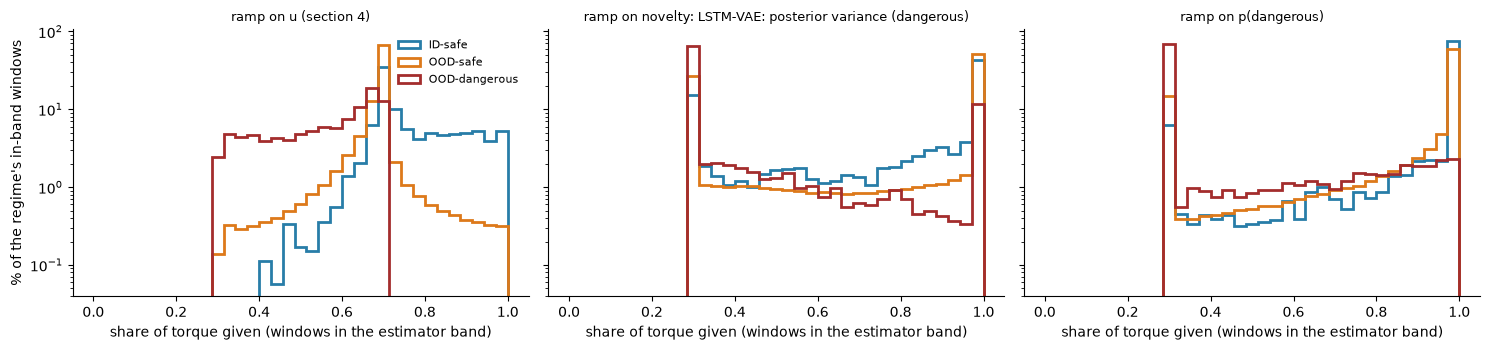

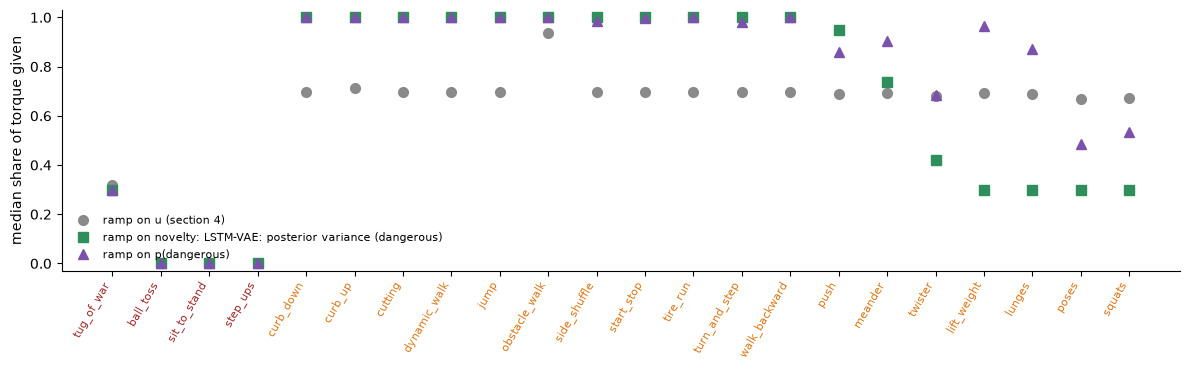

In [10]:
RAMP_C = dict(zip(['u (section 4)', *RAMPS], ['#8a8a8a', '#2f8f5b', '#7b52ab']))
fig, axes = plt.subplots(1, 3, figsize = (15, 3.6), sharey = True)
bins_g = np.linspace(0, 1, 36)
for ax, ramp in zip(axes, ['u (section 4)', *RAMPS]):
    g = np.concatenate([gains[seed, ramp] for seed in SEEDS])
    band_all = np.concatenate([get_band(rc.get_uncertainty(p_test[seed])) for seed in SEEDS])
    for r in rc.REGIMES:
        m = (y_test_all == r) & band_all
        ax.hist(g[m], bins = bins_g, weights = np.full(m.sum(), 100 / max(m.sum(), 1)), histtype = 'step', linewidth = 2, color = REGIME_C[r], label = r)
    ax.set(title = f'ramp on {ramp}', xlabel = 'share of torque given (windows in the estimator band)')
    ax.title.set_fontsize(9)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set(ylabel = "% of the regime's in-band windows", yscale = 'log')
axes[0].legend(frameon = False, fontsize = 8)
fig.tight_layout()
fig.savefig(FIG_DIR / '09_novelty_ramp.png', dpi = 160, bbox_inches = 'tight')
plt.show()

frame = pd.concat([pd.DataFrame({'task': task_test, 'regime': y['test'], 'ramp': ramp, 'g': gains[seed, ramp]})
                   for seed in SEEDS for ramp in ['u (section 4)', *RAMPS]])
frame = frame[frame['regime'] != ns.ID]
med = frame.groupby(['task', 'regime', 'ramp'])['g'].median().unstack('ramp').reset_index()
med = med.sort_values(['regime', list(RAMPS)[0]], ascending = [True, False]).reset_index(drop = True)
med.to_csv(RESULTS / '09_novelty_ramp_per_task.csv', index = False)
fig, ax = plt.subplots(figsize = (12, 3.8))
for (ramp, colour), marker in zip(RAMP_C.items(), ['o', 's', '^']):
    ax.plot(range(len(med)), med[ramp], marker, color = colour, markersize = 7, label = f'ramp on {ramp}', linestyle = 'none')
ax.set_xticks(range(len(med)), med['task'], rotation = 60, ha = 'right', fontsize = 8)
for k, r in enumerate(med['regime']):
    ax.get_xticklabels()[k].set_color(REGIME_C[r])
ax.set(ylabel = 'median share of torque given', ylim = (-.03, 1.03))
ax.legend(frameon = False, fontsize = 8, loc = 'lower left')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / '09_novelty_ramp_per_task.png', dpi = 160, bbox_inches = 'tight')
plt.show()

Per task under the $p_\text{dangerous}$ ramp (test participants, three seeds): top, $p_\text{dangerous}$ with the ramp's
anchors (mean over seeds; full torque below the lower, `JME_FLOOR` from the upper); bottom, the share of torque each task
is given (spline 1, exo off 0). Median and interquartile range, tasks in the order of the $u$ figure. The test probabilities
are saved to `results/09_test_proba.npz` so later figures need no rerun.

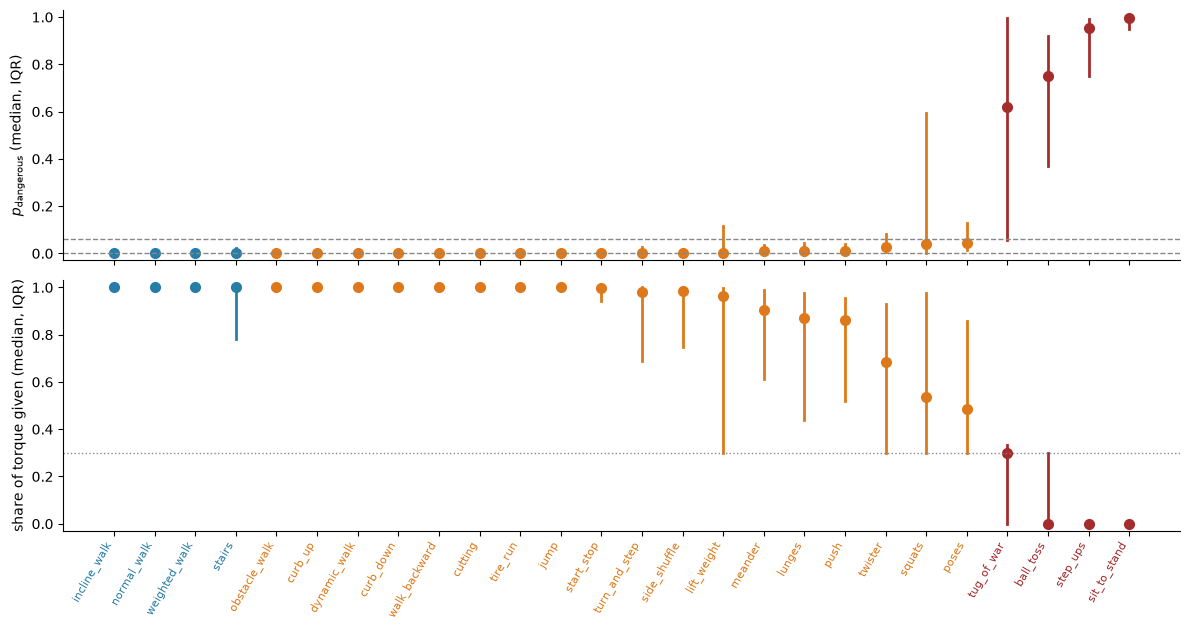

anchors (mean over seeds): [0.    0.062]


In [11]:
np.savez_compressed(RESULTS / '09_test_proba.npz', rec = rows['test']['rec'].to_numpy(), end = rows['test']['end'].to_numpy(),
                    **{f'{name} | s{seed}': test_p[seed, name] for seed in SEEDS for name in CONFIGS})
j_p = RAMPS['p(dangerous)']
lo_hi = np.mean([anchors[seed, j_p] for seed in SEEDS], axis = 0)
frame = pd.DataFrame({'task': np.tile(task_test, len(SEEDS)), 'regime': y_test_all,
                      'p': np.concatenate([p_test[seed][:, 2] for seed in SEEDS]),
                      'g': np.concatenate([gains[seed, 'p(dangerous)'] for seed in SEEDS])})
order = pd.read_csv(RESULTS / '09_uncertainty_per_task.csv')['task'].tolist()
stats = {c: frame.groupby('task')[c].quantile([.25, .5, .75]).unstack().reindex(order) for c in ('p', 'g')}
regime_of = frame.groupby('task')['regime'].first()
fig, axes = plt.subplots(2, 1, figsize = (12, 6.4), sharex = True)
for ax, c, label in ((axes[0], 'p', '$p_\\mathrm{dangerous}$ (median, IQR)'), (axes[1], 'g', 'share of torque given (median, IQR)')):
    for k, t in enumerate(order):
        q = stats[c].loc[t]
        ax.plot([k, k], [q[.25], q[.75]], color = REGIME_C[regime_of[t]], linewidth = 2)
        ax.plot(k, q[.5], 'o', color = REGIME_C[regime_of[t]], markersize = 7)
    ax.set(ylabel = label, ylim = (-.03, 1.03))
    ax.spines[['top', 'right']].set_visible(False)
for v in lo_hi:
    axes[0].axhline(v, color = '#888', linestyle = '--', linewidth = 1)
axes[1].axhline(JME_FLOOR, color = '#888', linestyle = ':', linewidth = 1)
axes[1].set_xticks(range(len(order)), order, rotation = 60, ha = 'right', fontsize = 8)
for k, t in enumerate(order):
    axes[1].get_xticklabels()[k].set_color(REGIME_C[regime_of[t]])
fig.tight_layout()
fig.savefig(FIG_DIR / '09_p_dangerous_ramp_per_task.png', dpi = 160, bbox_inches = 'tight')
plt.show()
print('anchors (mean over seeds):', lo_hi.round(3))

## 6. A dangerous task neither stage saw

Each dangerous task is removed from the validation windows of both stages (the classifier's out-of-fold probabilities are
recomputed without it); its test windows are then classified, and placed on the uncertainty score with section 4's cutoffs
(chosen with the task present, so this asks whether an unseen dangerous task still lands right of the cutoff), and given
section 5's novelty ramp inside the band (its anchors also chosen with the task present).

In [12]:
t0 = time.time()
DANGEROUS_TASKS = sorted(rows['test'].loc[rows['test']['controller_class'] == ns.DANGEROUS, 'task'].astype(str).unique())
held_rows = []
for seed in SEEDS:
    for task in DANGEROUS_TASKS:
        keep = rows['val']['task'].astype(str).to_numpy() != task
        on = (rows['test']['task'].astype(str) == task).to_numpy()
        lab_on = rows['test'][on].reset_index(drop = True)
        oof_k = get_oof_proba(base[seed]['val'], keep, seed)
        proba_t = get_proba(base[seed]['val'][keep], y['val'][keep], base[seed]['test'][on], lab_on, seed)
        for name, (kind, second) in CONFIGS.items():
            if kind is None:
                p_on = proba_t
            else:
                x_v = get_x(seed, 'val', kind, oof_k)
                x_t = novelty[seed]['test'][on] if kind == 'novelty' else np.concatenate([proba_t, novelty[seed]['test'][on]], axis = 1)
                p_on = get_second_proba(SECOND[second](seed), x_v[keep], y['val'][keep], x_t, lab_on)
            pred, u_on = get_pred(p_on), rc.get_uncertainty(p_on)
            held_rows.append({'configuration': name, 'seed': seed, 'task': task,
                              **{f'given {r} (%)': 100 * np.mean(pred == r) for r in rc.REGIMES},
                              'median uncertainty': np.median(u_on),
                              'switched off by the cutoff (%)': 100 * np.mean(u_on >= cutoffs[name][1]),
                              'mean assistance': rc.get_assistance(u_on, cutoffs[name], JME_FLOOR).mean(),
                              'mean assistance, novelty ramp': rc.get_ramped_assistance(
                                  u_on, sign[best_j] * novelty[seed]['test'][on][:, best_j], cutoffs[name], anchors[seed, best_j], JME_FLOOR).mean()})
held = pd.DataFrame(held_rows)
held.to_csv(RESULTS / '09_fusion_held_out.csv', index = False)
display(held.groupby(['configuration', 'task'], sort = False)[[f'given {r} (%)' for r in rc.REGIMES]].mean().round(1).unstack('task'))
display(held.groupby('configuration', sort = False)[[f'given {r} (%)' for r in rc.REGIMES] + ['median uncertainty', 'switched off by the cutoff (%)', 'mean assistance', 'mean assistance, novelty ramp']].mean().round(3))
print(f'{time.time() - t0:.0f} s')

given ID-safe (%)                                  given OOD-safe (%)                                  given OOD-dangerous (%)                                 
task                                         ball_toss sit_to_stand step_ups tug_of_war          ball_toss sit_to_stand step_ups tug_of_war               ball_toss sit_to_stand step_ups tug_of_war
configuration                                                                                                                                                                                       
regime classifier alone                            0.0          0.0      0.0        0.0               75.6         52.8     98.8       68.7                    24.4         47.2      1.2       31.3
novelty scores alone                               0.0          0.0      0.0        0.0               78.1         55.0     91.9       80.6                    21.9         45.0      8.1       19.4
confidence + novelty (boosted trees)               0.0          0.0      0.0        0.1               69.7         39.2     98.6       82.2                    30.3         60.8      1.4       17.8
confidence + novelty (logistic)                    0.0          0.0      0.6        0.2               53.4         22.2     98.2       59.7                    46.6         77.8      1.2       40.1

,given ID-safe (%),given OOD-safe (%),given OOD-dangerous (%),median uncertainty,switched off by the cutoff (%),mean assistance,"mean assistance, novelty ramp"
configuration,,,,,,,
regime classifier alone,0.002,73.950,26.049,0.580,21.551,0.496,0.345
novelty scores alone,0.000,76.401,23.599,0.568,17.692,0.520,0.360
confidence + novelty (boosted trees),0.019,72.415,27.566,0.605,15.818,0.658,0.366
confidence + novelty (logistic),0.189,58.376,41.435,0.697,25.086,0.451,0.335


856 s


## 7. What this shows

- **Regime choice:** the regime classifier alone stays the best decision; adding the other model types' novelty scores
  does not improve it on test or in cross-validation.
- **The uncertainty axis:** collapsing its probabilities to $u$ loses nothing for the decision and gives one dial with
  two cutoffs. The exo-off cutoff is the safety knob; the trade-off curve is what to choose it from, and the
  validation-F1 cutoff (0.825) favours not switching off safe walking over catching every dangerous window.
- **Scaling the estimator's torque:** $u$ is the wrong signal for this as built. A classifier trained to name the regime
  pushes OOD-safe windows to $u \approx 0.5$ regardless of how unfamiliar they are, so a ramp in $u$ is nearly a constant.
  A graded signal within OOD-safe has to come from something continuous in unfamiliarity: a novelty score (notebook 05's
  OOD-safe vs familiar AUROC ≈ 0.94 to 0.96 on 3 s raw) or, better, the estimator's own expected error.
- **Torque ramp (section 5):** a novelty score gives the graded signal $u$ lacks, but it tracks unfamiliarity rather than
  danger; $p_\text{dangerous}$ is the better ramp signal now. Which is right depends on what the estimator gets wrong,
  which is the next measurement.
- **Unseen dangerous tasks** mostly end up in the estimator band, at reduced torque; the shutdown itself depends on
  having seen the task.

**Next.** (1) Ramp the estimator's torque on a novelty score (or on $p_\text{dangerous}$ alone) inside the band, and
start the ramp at the OOD-safe centre rather than at the first cutoff. (2) Measure the estimator's error against that
signal, so the ramp is fitted rather than assumed (`JME_FLOOR` and the linear shape are placeholders). (3) Fit both
stages on the training participants as well (encode their windows); here only 4 people fit them.